### 환경 설정
- Jupyter Notebook, Python 3.x  
- OpenCV 라이브러리 설치:
  - 컴퓨터 비전 분야는 사람이 시각 정보를 입력값으로 하여 행동하기 이전에 생각하고 판단하는 부분을 컴퓨터가 대신하도록 하는 학문, 시각적인 입력 데이터, 즉 영상을 주로 다룸
  - OpenCV는 Computer Vision 관련 프로그래밍을 쉽게 할 수 있도록 도와주는 Open Library
  - OpenCV는 영상처리, 3D 구성, 추적, 기계학습, 인식 그리고 딥러닝까지 유용한 기능 많음, 상업적인 사용까지 무료
- Anaconda Prompt 에서 다음 명령 수행
> pip install opencv-python

In [17]:
import cv2

cv2.__version__

'5.0.0'

- 이미지 출력

In [ ]:
# cv2 라는 라이브러리가 자체적으로 가지고 있는 이미지 출력 기능
img = cv2.imread("./data/pets.jpg")
# opencv 이미지 출력
cv2.imshow("img", img)
cv2.waitKey(0)          # 0 : 무한 대기 // 지정된 시간동안 사용자 키 입력 대기
cv2.destroyAllWindows() # 모든 창 닫기

- 읽기 옵션

In [ ]:
# 컬러 이미지, 흑백 이미지, 투명 영역 포함
img_color = cv2.imread("./data/pets.jpg", cv2.IMREAD_COLOR)
img_gray = cv2.imread("./data/pets.jpg", cv2.IMREAD_GRAYSCALE)

# opencv 이미지 출력
cv2.imshow("img", img_color)
cv2.imshow("img", img_gray)

cv2.waitKey(0)          # 0 : 무한 대기 // 지정된 시간동안 사용자 키 입력 대기
cv2.destroyAllWindows() # 모든 창 닫기

- 이미지 정보 확인

In [ ]:
print("color :", img_color.shape)
print("gray :", img_gray.shape)

color : (427, 640, 3)
gray : (427, 640)


- Matplotlib 라이브러리로 이미지 출력

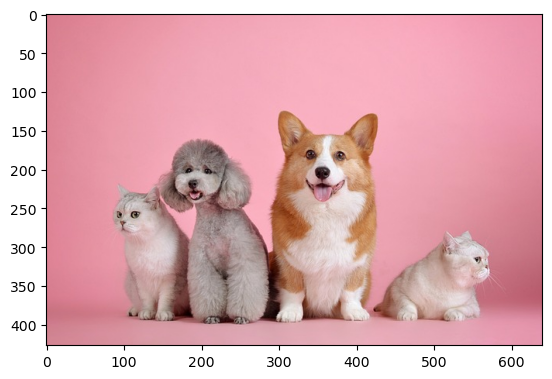

In [ ]:
import matplotlib.pyplot as plt
img = cv2.imread("./data/pets.jpg", cv2.IMREAD_COLOR)
# 색상 순서가 반전돼서 보여진다. -> 색상공간변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

## <색상공간 변환>
- 시각은 색상정보에 대해 잘못된 정보를 보내주는 경우가 많음
    - 밤에 색상을 볼때 정확한 색상을 보여주지 못함 - 명도 (검정색이 섞이는 것)
    - 색상에 빛을 강하게 비추는 경우 정확한 색상을 보여주지 못함 - 채도 (흰색이 섞이는 것)
    - 칼라는 너무 많은 정보를 가지고 있기때문에 연산량이 많음 - 실시간 처리가 어려움
    - 따라서 gray 이미지나 binary 이미지로 변환해서 처리
    - gray 이미지 : 0-255로 된 픽섹로만 구성된 흑백이미지
    - 이진 이미지 : 검정색(0)과 흰색(255)으로만 구성된 이미지, 0과 1로 이루어진 이미지
        - 특정 패턴이나 물체의 윤곽을 감지
        - 배경/물체 구별
        - 텍스트 필터링
        - 뼈의 윤곽/mri스캔 종양 식별
        - 자율주행시 장애물/차선 등 감지
        - 제품 결함 및 불량품 식별 등 사용가능

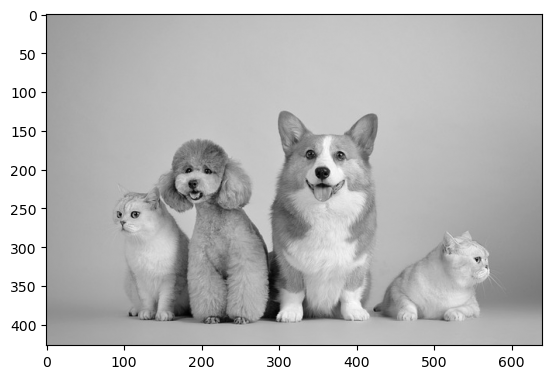

In [ ]:
img = cv2.imread("./data/pets.jpg", cv2.IMREAD_COLOR)

# 색상 순서가 반전돼서 보여진다. -> 색상공간변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) # 색상공간을 이진이미지로 변환 

plt.imshow(img, cmap = 'gray')
plt.show()

#### 이진(Binary) 이미지 구성(이미지 이진화)
 - 0,1(255) 데이터 구성하기
 - cv2.threshold(img, threshold_value, value, flag)
  - img : Grayscale 이미지
  - threshold_value : 픽셀 임계값 (0과 1로 나누기 위한 기준값)
  - value : 임계값보다 클 때 적용되는 값
  - flag : 임계값 적용 방법
    - cv2.THRESH_BINARY : 임계값보다 픽셀값이 크면 value, 아니면 0을 할당
    - cv2.THRESH_BINARY_INV : 임계값보다 픽셀값이 크면 0, 아니면 value를 할당  (cv2.THRESH_BINARY 반대)
    - cv2.THRESH_TRUNC : 임계값보다 큰 픽셀 값은 모두 임계값, 아니면 픽셀값은 변경되지 않음 (이미지 밝기 조절에 사용, 밝은 영역을 어둡게 만들어 세부 정보 잘 드러나게)

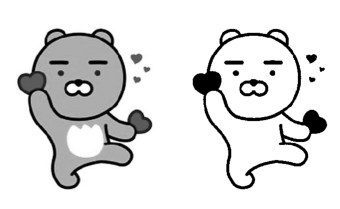

In [ ]:
# 이미지 불러오기 -> 흑백
img = cv2.imread("./data/ryan.jpg", cv2.IMREAD_GRAYSCALE)

# 이미지 이진화
_, thr_img = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY)
# 임곗값, 변형된이미지 = cv2.threshold(대상이미지, 임곗값(기준값), 최대값, 이진화 종류값)

# subplot
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, cmap = 'gray')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(thr_img, cmap = 'gray')

plt.show()

- 임곗값 찿기

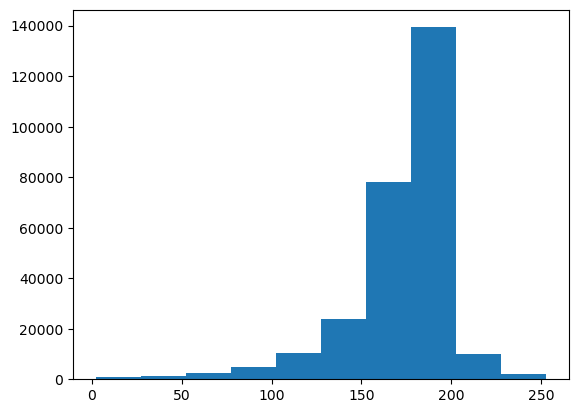

In [ ]:
# 히스토그램
img.reshape(-1).shape
plt.hist(img.reshape(-1))
plt.show()

- 자동으로 임곗값을 찿아주는 기능 : Otsu(오츠)의 이진화

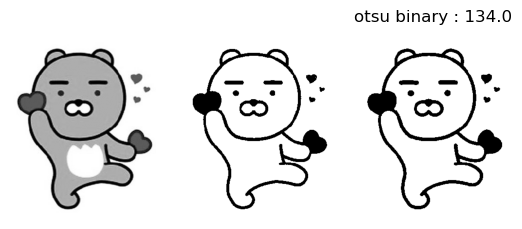

In [ ]:
# 이미지 불러오기 -> 흑백
img = cv2.imread("./data/ryan.jpg", cv2.IMREAD_GRAYSCALE)

# 이미지 이진화
_, thr_img = cv2.threshold(img, 100, 255, cv2.THRESH_BINARY)
# 임곗값, 변형된이미지 = cv2.threshold(대상이미지, 임곗값(기준값), 최대값, 이진화 종류값)
# 오츠 이진화
th_val, thr_img2 = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)

# subplot
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, cmap = 'gray')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(thr_img, cmap = 'gray')

plt.subplot(1, 3, 3)
plt.title(f"otsu binary : {th_val}")
plt.axis('off')
plt.imshow(thr_img2, cmap = 'gray')

plt.show()

#### 텍스트 인식(OCR)
 - 텍스트가 담긴 이미지를 기계가 읽을 수 있는 텍스트 포맷으로 변환하는 과정
 - 이미지 > TEXT
 - Pytesseract 모듈 사용
 - https://github.com/UB-Mannheim/tesseract/wiki

In [1]:
# 모듈 설치 (tesseract 엔진은 터미널에서: brew install tesseract tesseract-lang)
%pip install pytesseract

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 라이브러리 불러오기
import pytesseract as pyt

In [3]:
pyt.pytesseract.tesseract_cmd = "/opt/homebrew/bin/tesseract"  # Mac(Homebrew) 경로

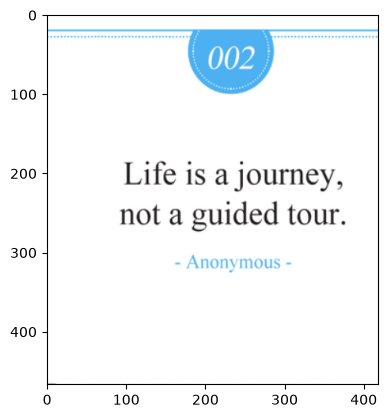

In [4]:
import matplotlib.pyplot as plt
import cv2
img = cv2.imread("./data/text.png", cv2.IMREAD_COLOR)
# 색상공간변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

In [5]:
text = pyt.image_to_string(img, lang = 'eng')
print(text)

Life is a journey,
not a guided tour.

- Anonymous -



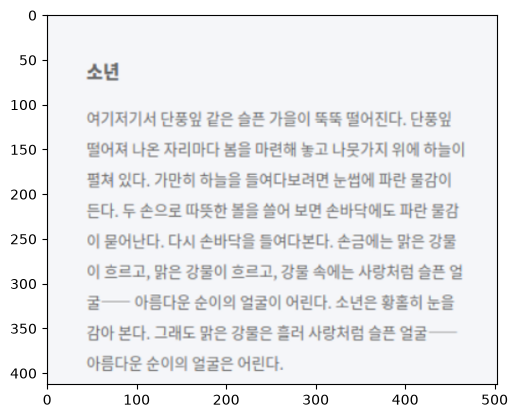

In [6]:
# 한국어 읽어오기 -> kor
img = cv2.imread("./data/story.png", cv2.IMREAD_COLOR)
# 색상공간변환
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)
plt.show()

In [7]:
text = pyt.image_to_string(img, lang = 'kor')
print(text)

소년

여기저기서 단풍잎 같은 슬픈 가을이 뚝뚝 떨어진다. 단풍잎
떨어져 나온 자리마다 봄을 마련해 놓고 나못가지 위에 하늘이
펼쳐 있다. 가만히 하늘을 들여다보려면 눈썸에 파란 물감이
든다. 두 손으로 따뜻한 볼을 쓸어 보면 손바닥에도 파란 물감
이 묻어난다. 다시 손바닥을 들여다본다. 손금에는 맑은 강물
이 흐르고, 맑은 강물이 흐르고, 강물 속에는 사랑처럼 슬픈 얼
굴ㅡ- 아름다운 순이의 얼굴이 어린다. 소년은 황홀히 눈을
감아 본다. 그래도 맑은 강물은 흘러 사랑처럼 슬픈 얼굴--
아름다운 순이의 얼굴은 어린다.

